<a href="https://colab.research.google.com/github/davichomendez1901-byte/Simulaci-n-Remix/blob/main/ModeloSIR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo SIR con Metropolis-Hastings

## Ajuste de parámetros mediante MCMC

El objetivo de este trabajo es ajustar los parámetros del modelo epidemiológico
SIR a un conjunto de datos escolares, utilizando inicialmente un ajuste por
mínimos cuadrados y posteriormente el método de **Metropolis-Hastings**.

El modelo SIR divide a la población en tres grupos:

- **S(t):** individuos susceptibles.
- **I(t):** individuos infectados.
- **R(t):** individuos recuperados.

A partir de los datos observados de individuos infectados se estimarán los
parámetros asociados con la infección y la recuperación. Posteriormente,
mediante MCMC se estudiará la incertidumbre y la relación existente entre
ambos parámetros.

In [4]:
#Importacion de librerias.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st # Importar scipy.stats
import seaborn as sns # Importar seaborn para los histogramas

## 1. Datos observados

Se cuenta con una serie de datos que representa el número de individuos
infectados observado en distintos instantes de tiempo:

$$
I_{\mathrm{obs}} =
[1,3,6,25,73,222,294,258,237,191,125,69,27,11,4].
$$

Primero se realiza una gráfica de los datos para observar el comportamiento
de la propagación. Se aprecia inicialmente un crecimiento en el número de
infectados, seguido de un máximo y posteriormente una disminución.

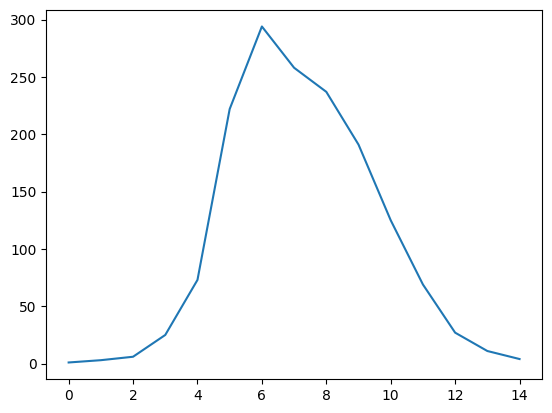

In [5]:
#Datos Escolares
school_data = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4 ]
#Grafica de datos escolares.
plt.plot(school_data)
plt.show()

## 2. Formulación del modelo SIR

Para representar la propagación de la enfermedad se utiliza el modelo
epidemiológico **SIR**, en el cual la población se divide en tres grupos:

- $S(t)$: individuos susceptibles.
- $I(t)$: individuos infectados.
- $R(t)$: individuos recuperados.

La dinámica del modelo está dada por el siguiente sistema de ecuaciones
diferenciales:

$$
\frac{dS}{dt}=-aSI
$$

$$
\frac{dI}{dt}=aSI-bI
$$

$$
\frac{dR}{dt}=bI
$$

donde:

- $a$ representa la **tasa de infección**.
- $b$ representa la **tasa de recuperación**.

El objetivo será encontrar valores adecuados de $a$ y $b$ para que la
componente $I(t)$ del modelo reproduzca lo mejor posible los datos
observados de individuos infectados.

In [6]:
# Sistema de ecuaciones del modelo SIR.
def deriv(Y, t, N, a, b):
    S, I, R = Y
    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I
    return dSdt, dIdt, dRdt

In [7]:
# Importaciones adicionales para el ajuste.
from scipy.integrate import odeint
from scipy.optimize import curve_fit

## 3. Condiciones iniciales y preparación del ajuste

Para resolver numéricamente el modelo SIR es necesario establecer las
condiciones iniciales de la población.

Se considera, como supuesto del modelo, una población total de:

$$
N = 1000
$$

El primer dato observado corresponde a un individuo infectado, por lo que:

$$
I(0)=1
$$

Se supone que inicialmente no existen individuos recuperados:

$$
R(0)=0
$$

Por lo tanto, el número inicial de susceptibles es:

$$
S(0)=N-I(0)-R(0)=999.
$$

Así, el vector de condiciones iniciales es:

$$
Y_0=(999,1,0).
$$

Estas condiciones se utilizarán para resolver numéricamente el sistema SIR
y posteriormente ajustar los parámetros $a$ y $b$ a los datos observados.

In [8]:
# Proponiendo una población total como 1000
N = 1000
# Número inicial de infectados (I0) y recuperados (R0)
I0 = school_data[0]
R0 = 0
# Los demás, S0, son susceptibles inicialmente.
S0 = N - I0 - R0

# Vector de condiciones iniciales
Y0 = S0, I0, R0

# Puntos de tiempo (días)
t = np.arange(len(school_data))

# Modelo SIR para ajuste de curva
def sir_model(t, a, b):
    # Resolver la EDO para 'a' y 'b'
    # Y0, t, N son fijos para el ajuste
    ret = odeint(deriv, Y0, t, args=(N, a, b))
    I_fitted = ret[:, 1] # Ajustar el componente 'I'
    return I_fitted

## 4. Ajuste inicial de los parámetros

Una vez definido el modelo SIR y sus condiciones iniciales, se realiza un
primer ajuste de los parámetros $a$ y $b$.

Para ello se utiliza `curve_fit`, que busca los valores de los parámetros
que minimizan la diferencia cuadrática entre los datos observados de
infectados y los valores de $I(t)$ generados por el modelo SIR.

Se proporcionan como valores iniciales:

$$
a_0=0.001, \qquad b_0=0.1.
$$

Estos valores solamente funcionan como punto de partida para el proceso de
optimización.

El resultado de este ajuste proporciona los valores $a_{\mathrm{opt}}$ y
$b_{\mathrm{opt}}$, que posteriormente serán utilizados como punto inicial
del algoritmo de Metropolis-Hastings.

'a' optimizado (tasa de infección): 0.0018
'b' optimizado (tasa de recuperación): 0.5849


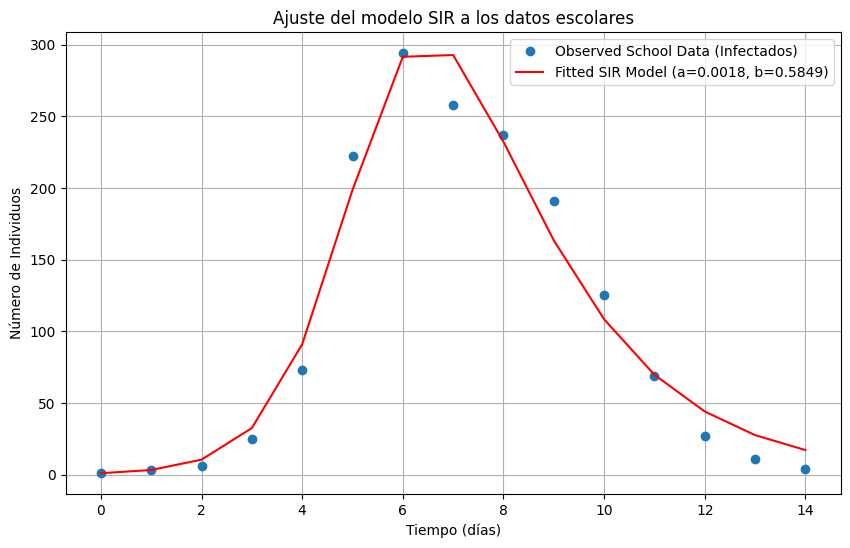

In [9]:
# Estimación inicial para 'a' y 'b'
p0 = [0.001, 0.1]

# Ajuste de curva
params, pcov = curve_fit(sir_model, t, school_data, p0)

# Parámetros optimizados
a_opt, b_opt = params

print(f"'a' optimizado (tasa de infección): {a_opt:.4f}")
print(f"'b' optimizado (tasa de recuperación): {b_opt:.4f}")

# Graficar ajuste vs datos reales
plt.figure(figsize=(10, 6))
plt.plot(t, school_data, 'o', label='Observed School Data (Infectados)')
plt.plot(t, sir_model(t, a_opt, b_opt), "red", label=f'Fitted SIR Model (a={a_opt:.4f}, b={b_opt:.4f})')
plt.xlabel('Tiempo (días)')
plt.ylabel('Número de Individuos')
plt.title('Ajuste del modelo SIR a los datos escolares')
plt.legend()
plt.grid(True)
plt.show()

## 5. Función de error $\chi^2$

Para evaluar qué tan bien un par de parámetros $(a,b)$ reproduce los datos
observados, se define una función de error basada en la suma de cuadrados:

$$
\chi^2(a,b)=
\sum_{i=1}^{n}
\left[I_{\mathrm{obs}}(t_i)-I_{\mathrm{SIR}}(t_i;a,b)\right]^2.
$$

Para cada par $(a,b)$ se resuelve nuevamente el sistema SIR y se compara
la componente de infectados $I(t)$ con los datos escolares.

Un valor pequeño de $\chi^2$ representa un mejor ajuste del modelo a los
datos observados.


In [10]:
def chi2(a,b):
  #Resolver el modelo SIR con a y b
  sol = odeint(deriv, Y0, t, args=(N, a, b))
  #Extraemos solamento los infectados:
  I_model = sol[:,1]
  #Calculamos Chi-cudrada.
  error = np.array(school_data) - I_model
  chi = np.sum(error**2)
  return chi

In [11]:
chi2_opt = chi2(a_opt, b_opt)
print("a=", a_opt)
print("b=", b_opt)
print(f"C,hi-cuadrada inicial: {chi2_opt:.4f}")

a= 0.00176893524849669
b= 0.5848653252977286
C,hi-cuadrada inicial: 3957.2929


In [12]:
a_actual = a_opt
b_actual = b_opt
#Propongamos un nuevo punto cercano:
a_nuevo = np.random.normal(a_actual, 0.000005)
b_nuevo = np.random.normal(b_actual, 0.01)


In [13]:
chi_actual = chi2(a_actual, b_actual)
chi_nuevo = chi2(a_nuevo, b_nuevo)
print(f"Chi-cuadrada actual: {chi_actual:.4f}")
print(f"Chi-cuadrada nuevo: {chi_nuevo:.4f}")


Chi-cuadrada actual: 3957.2929
Chi-cuadrada nuevo: 4026.7915


## 7. Regla de aceptación de Metropolis-Hastings

Se compara el ajuste del estado propuesto con el del estado actual mediante

$$
\Delta\chi^2=
\chi^2_{\text{nuevo}}-\chi^2_{\text{actual}}.
$$

La probabilidad de aceptación se calcula como

$$
\alpha=
\min\left(1,e^{-\Delta\chi^2/2}\right).
$$

Si el nuevo estado produce un menor valor de $\chi^2$, entonces
$\Delta\chi^2<0$ y la propuesta se acepta con probabilidad 1.

Si el nuevo estado produce un mayor valor de $\chi^2$, todavía puede ser
aceptado con cierta probabilidad. Esta característica permite que la cadena
explore el espacio de parámetros y evita limitar el procedimiento a una
búsqueda determinista del mínimo.

Finalmente se genera

$$
u\sim U(0,1)
$$

y se acepta la propuesta cuando $u<\alpha$. En caso contrario, la propuesta
es rechazada y la cadena permanece en el estado actual.

In [14]:
delta_chi = chi_nuevo - chi_actual
prob_aceptacion = min(1,np.exp(-delta_chi/2))
print("Diferencia de chi", delta_chi)
print("Probabilidad de aceptación", prob_aceptacion)

Diferencia de chi 69.49853971863831
Probabilidad de aceptación 8.101843501700205e-16


In [15]:
u = np.random.uniform(0,1)
if u < prob_aceptacion:
  a_actual = a_nuevo
  b_actual = b_nuevo
  print("Aceptado")
else:
  print("Rechazado")

Rechazado


In [16]:
#Numero de iteraciones que haremos:
n_iter = 10000
#Comenzando desde los parametros optimos:
a_actual = a_opt
b_actual = b_opt
#Creamos espacios para guardar las cadenas:
a_chain = []
b_chain = []
#contador de aceptaciones
aceptados = 0

In [17]:
# Aseguramos que a_actual y b_actual comiencen desde los parámetros óptimos
a_actual = a_opt
b_actual = b_opt

# Reiniciamos las cadenas y el contador de aceptaciones para una nueva ejecución
a_chain = []
b_chain = []
aceptados = 0

# Añadimos los valores iniciales a las cadenas
a_chain.append(a_actual)
b_chain.append(b_actual)

for i in range(n_iter):
  # 1. Proponemos nuevos valores
  a_nuevo = np.random.normal(a_actual, 0.000005)
  b_nuevo = np.random.normal(b_actual, 0.001)

  # Si los valores propuestos son inválidos (menor o igual a cero), se rechazan
  # y se mantiene el estado actual (se añade el estado actual a la cadena).
  if a_nuevo <= 0 or b_nuevo <= 0:
    a_chain.append(a_actual)
    b_chain.append(b_actual)
    continue # Saltar a la siguiente iteración

  # 2. Calculamos chi-cuadrada para el estado actual y el propuesto
  chi_actual = chi2(a_actual, b_actual)
  chi_nuevo = chi2(a_nuevo, b_nuevo)

  # 3. Calculamos la probabilidad de aceptación
  delta_chi = chi_nuevo - chi_actual
  prob_aceptacion = min(1, np.exp(-delta_chi/2))

  # 4. Generamos un número uniforme aleatorio
  u = np.random.uniform(0,1)

  # 5. Decisión de aceptación o rechazo
  if u < prob_aceptacion:
    a_actual = a_nuevo
    b_actual = b_nuevo
    aceptados += 1
  # Si se rechaza, a_actual y b_actual conservan sus valores previos.

  # 6. Añadimos el estado (actualizado o retenido) a las cadenas al final de cada iteración
  a_chain.append(a_actual)
  b_chain.append(b_actual)


In [18]:
tasa_aceptacion = aceptados/n_iter
print("Tasa de aceptación", tasa_aceptacion)
print("Numero de aceptados", aceptados)
print("Ultimo valor de a", a_actual)
print("Ultimo valor de b", b_actual)
#

Tasa de aceptación 0.2191
Numero de aceptados 2191
Ultimo valor de a 0.0017678010506631092
Ultimo valor de b 0.5831683137819282


## 8. Construcción de la cadena de Markov mediante Metropolis-Hastings

Una vez establecida la regla de aceptación, el procedimiento se repite
durante un número determinado de iteraciones para construir una cadena
de valores de los parámetros $a$ y $b$.

En cada iteración:

1. Se propone un nuevo par $(a^*,b^*)$ alrededor del estado actual.
2. Se calcula $\chi^2$ para el estado actual y para el propuesto.
3. Se obtiene la probabilidad de aceptación:

$$
\alpha =
\min\left(
1,
\exp\left[-\frac{\chi^2_{\mathrm{nuevo}}
-\chi^2_{\mathrm{actual}}}{2}\right]
\right).
$$

4. Se genera un número aleatorio $u\sim U(0,1)$.
5. Si $u<\alpha$, la propuesta es aceptada; de lo contrario,
la cadena permanece en el estado anterior.

Este procedimiento se repetirá 10 000 veces y se almacenarán los valores
de $a$ y $b$ obtenidos en cada iteración.

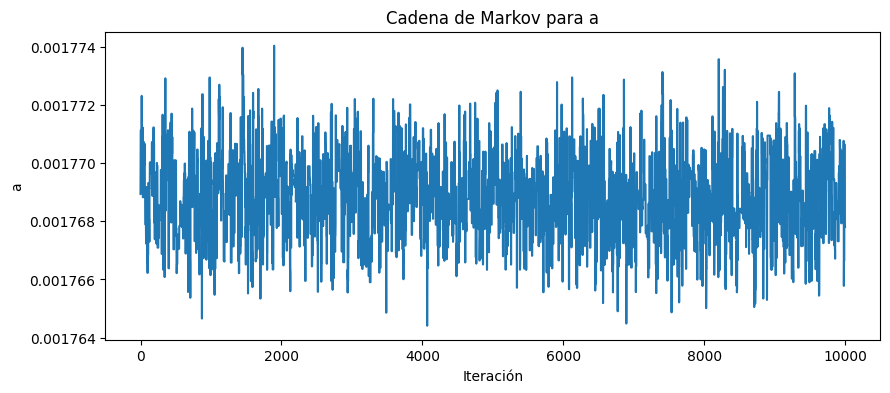

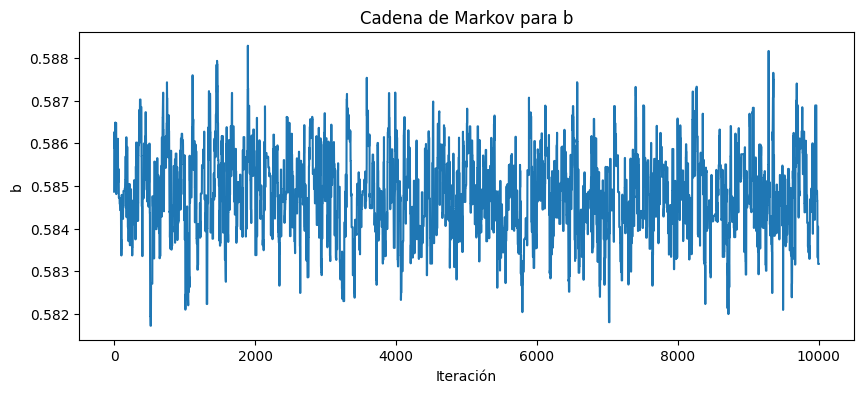

In [19]:
plt.figure(figsize=(10,4))
plt.plot(a_chain)
plt.xlabel("Iteración")
plt.ylabel("a")
plt.title("Cadena de Markov para a")
plt.show()

plt.figure(figsize=(10,4))
plt.plot(b_chain)
plt.xlabel("Iteración")
plt.ylabel("b")
plt.title("Cadena de Markov para b")
plt.show()

### Interpretación

Las cadenas de los parámetros $a$ y $b$ fluctúan alrededor de regiones
relativamente estables, sin presentar una tendencia creciente o decreciente
sistemática a lo largo de las iteraciones.

Esto indica que el algoritmo está explorando una región alrededor de los
valores de los parámetros que proporcionan un buen ajuste al modelo SIR.

Los valores repetidos que pueden observarse en las cadenas corresponden a
iteraciones en las que la nueva propuesta fue rechazada y, por lo tanto,
se conservó el estado anterior.

## 9. Eliminación del periodo de calentamiento (Burn-in)

Las primeras iteraciones de una cadena MCMC pueden estar influenciadas por los
valores iniciales utilizados en el algoritmo. Por esta razón, se descarta una
parte inicial de la cadena, conocida como **periodo de burn-in**.

En este caso se eliminarán las primeras **2000 iteraciones** de las cadenas de
los parámetros $a$ y $b$.

A partir de las muestras restantes se estimarán:

- Las medias de $a$ y $b$.
- La matriz de covarianza.
- La correlación entre ambos parámetros.
- La región conjunta representada mediante elipses de confianza.

In [20]:
#Numero de iteraciones que descartaremos:
burn_in = 2000

#Eliminar las primeras 2000 iteraciones:

a_muestra = np.array(a_chain[burn_in:])
b_muestra = np.array(b_chain[burn_in:])

print("muestras restantes:", len(a_muestra))

muestras restantes: 8001


In [21]:
#medias de los parametros:
media_a = np.mean(a_muestra)
media_b = np.mean(b_muestra)
print("Media de a", media_a)
print("Media de b", media_b)

Media de a 0.0017687866636982195
Media de b 0.5847452472296338


### Estimación de los parámetros

Después de eliminar las primeras 2000 iteraciones, las medias de las muestras
MCMC se utilizan como estimaciones de los parámetros del modelo.

Se obtienen aproximadamente:

$$
\bar{a} \approx 0.001769,
\qquad
\bar{b} \approx 0.58475.
$$

Estos valores representan la región alrededor de la cual se concentra la
mayor parte de las muestras generadas por el algoritmo.

In [22]:
#matriz de covarianza:
Sigma = np.cov(a_muestra, b_muestra)
print("Matriz de covarianza")
print(Sigma)

Matriz de covarianza
[[1.87498288e-12 7.53812386e-10]
 [7.53812386e-10 9.63927244e-07]]


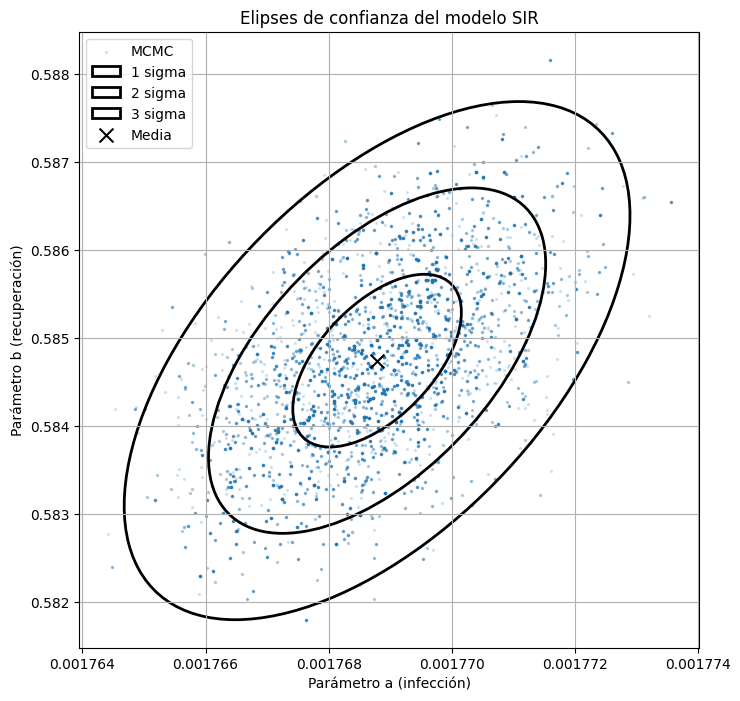

In [23]:
from matplotlib.patches import Ellipse
#calculo de autovalores y autovectores:
valores, vectores = np.linalg.eig(Sigma)
#Ordenamiento de mayor a menor:
orden = valores.argsort()[::-1]
valores = valores[orden]
vectores = vectores[:,orden]
#Angulo de rotacion de la elipse:
angulo = np.degrees(
    np.arctan2(vectores[1,0],vectores[0,0])
    )
#Creacion de la grafica:
fig, ax = plt.subplots(figsize=(8,8))

#Nube de puntos MCMC
ax.scatter(
    a_muestra,
    b_muestra,
    s=2,
    alpha = 0.15,
    label = "MCMC"
)

# Construir las tres elipses
for k in [1, 2, 3]:

    ancho = 2 * k * np.sqrt(valores[0])
    alto = 2 * k * np.sqrt(valores[1])

    elipse = Ellipse(
        (media_a, media_b),
        width=ancho,
        height=alto,
        angle=angulo,
        fill=False,
        linewidth=2,
        label=f"{k} sigma"
    )

    ax.add_patch(elipse)

# Centro de las elipses
ax.scatter(
    media_a,
    media_b,
    marker="x",
    s=100,
    color="black",
    label="Media"
)

ax.set_xlabel("Parámetro a (infección)")
ax.set_ylabel("Parámetro b (recuperación)")
ax.set_title("Elipses de confianza del modelo SIR")

ax.legend()
ax.grid(True)
plt.show()



## 10. Elipse de confianza de los parámetros

Para analizar conjuntamente la variabilidad de los parámetros $a$ y $b$,
se utiliza la matriz de covarianza obtenida a partir de las muestras MCMC.

La elipse permite visualizar tanto la dispersión de los parámetros como la
relación existente entre ellos. Su centro corresponde aproximadamente al
vector de medias

$$
\boldsymbol{\mu} =
\begin{pmatrix}
\bar a\\
\bar b
\end{pmatrix}.
$$

La orientación de las elipses está determinada por la covarianza entre ambos
parámetros. Una inclinación positiva indica que valores mayores de $a$
tienden a estar asociados con valores mayores de $b$.

In [24]:
#Correlacion entre los parametros:
correlacion = np.corrcoef(a_muestra, b_muestra)
print("Correlacion entre los parametros")
print(correlacion)

Correlacion entre los parametros
[[1.         0.56071541]
 [0.56071541 1.        ]]


### Interpretación de la correlación

La matriz de correlación obtenida es aproximadamente

$$
\begin{pmatrix}
1 & 0.561\\
0.561 & 1
\end{pmatrix}.
$$

Por lo tanto, la correlación entre los parámetros $a$ y $b$ es

$$
\rho_{a,b} \approx 0.561.
$$

Este valor indica una **correlación positiva moderada** entre ambos parámetros.
Es decir, dentro de las muestras generadas por MCMC, valores mayores de $a$
tienden a estar asociados con valores mayores de $b$.

Este comportamiento coincide con la orientación positiva observada
anteriormente en las elipses de confianza.

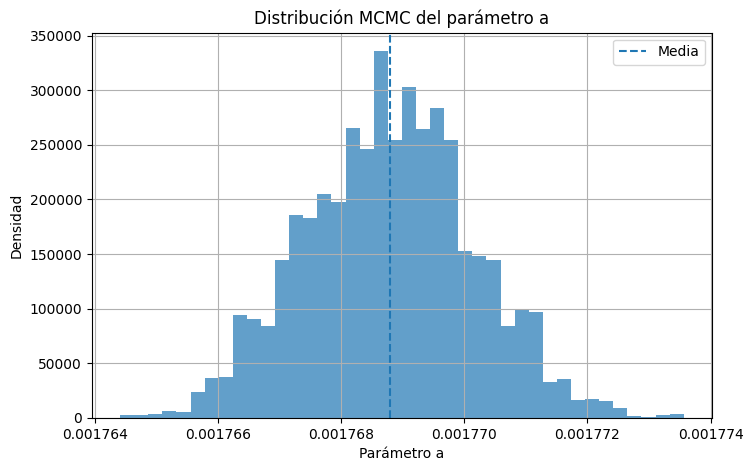

In [27]:
# Histogramas de los parámetros después del burn-in
import matplotlib.pyplot as plt



plt.figure(figsize=(8, 5))
plt.hist(a_muestra, bins=40, density=True, alpha=0.7)

plt.axvline(media_a, linestyle='--', label='Media')

plt.xlabel('Parámetro a')
plt.ylabel('Densidad')
plt.title('Distribución MCMC del parámetro a')
plt.legend()
plt.grid(True)
plt.show()




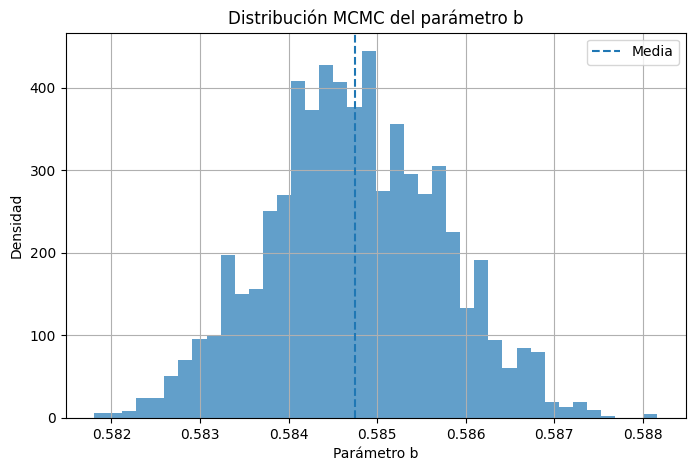

In [26]:
plt.figure(figsize=(8, 5))
plt.hist(b_muestra, bins=40, density=True, alpha=0.7)

plt.axvline(media_b, linestyle='--', label='Media')

plt.xlabel('Parámetro b')
plt.ylabel('Densidad')
plt.title('Distribución MCMC del parámetro b')
plt.legend()
plt.grid(True)
plt.show()

### Interpretación de los histogramas

Los histogramas muestran la distribución de los valores de los parámetros
$a$ y $b$ obtenidos mediante MCMC después de eliminar el periodo de *burn-in*.

En ambos casos se observa una mayor concentración de las muestras alrededor
de los valores medios estimados:

$$
a \approx 0.001769,
\qquad
b \approx 0.58475.
$$

El parámetro $a$ presenta una distribución concentrada aproximadamente
alrededor de $0.001769$, mientras que el parámetro $b$ se concentra alrededor
de $0.585$. La disminución de la frecuencia hacia los extremos indica que
valores alejados de estas regiones fueron menos frecuentes en las muestras
generadas.

La dispersión de los histogramas representa la variabilidad de los parámetros
dentro de la muestra MCMC. Por lo tanto, el procedimiento no proporciona
únicamente una estimación puntual de $a$ y $b$, sino también información sobre
el rango de valores explorados por la cadena.

En conjunto, los histogramas, las cadenas de Markov y las elipses obtenidas
permiten visualizar tanto el comportamiento individual de cada parámetro como
la relación existente entre ambos.

### Interpretación de los histogramas

Los histogramas muestran la distribución de los valores de los parámetros
$a$ y $b$ obtenidos mediante MCMC después de eliminar el periodo de *burn-in*.

En ambos casos se observa una mayor concentración de las muestras alrededor
de los valores medios estimados:

$$
a \approx 0.001769,
\qquad
b \approx 0.58475.
$$

El parámetro $a$ presenta una distribución concentrada aproximadamente
alrededor de $0.001769$, mientras que el parámetro $b$ se concentra alrededor
de $0.585$. La disminución de la frecuencia hacia los extremos indica que
valores alejados de estas regiones fueron menos frecuentes en las muestras
generadas.

La dispersión de los histogramas representa la variabilidad de los parámetros
dentro de la muestra MCMC. Por lo tanto, el procedimiento no proporciona
únicamente una estimación puntual de $a$ y $b$, sino también información sobre
el rango de valores explorados por la cadena.

En conjunto, los histogramas, las cadenas de Markov y las elipses obtenidas
permiten visualizar tanto el comportamiento individual de cada parámetro como
la relación existente entre ambos.